# Interpretability

Interpretability is the ability to understand and explain how a deep learning model is making decisions. One of the challenges in deep learning is that models are often composed of many layers of interconnected neurons, which can make it difficult to understand how the model is using the input data to make predictions. There are a number of approaches that have been developed to improve the interpretability of deep learning models, including techniques that allow for the visualization of the internal workings of the model and methods that simplify the model to make it more transparent. Research in this area is ongoing, and as the field of deep learning continues to evolve, it is expected that new methods for improving the interpretability of deep learning models will be developed.


# CNN Visualization

It is often said that deep learning models are “black boxes”, learning representations that are difficult to extract and present in a human-readable form. While this is partially true for certain types of deep learning models, it is definitely not true for convnets. The representations learned by convnets are highly amenable to visualization, in large part because they are representations of visual concepts. A wide array of techniques have been developed for visualizing and interpreting these representations. We won't survey all of them, but we will cover two of the most accessible and useful ones:


*   Visualizing heatmaps of class activation in an image. This is useful to understand which part of an image were identified as belonging to a given class, and thus allows to localize objects in images.
*   Visualizing intermediate convnet outputs (“intermediate activations”). This is useful to understand how successive convnet layers transform their input, and to get a first idea of the meaning of individual convnet filters.

# Sample network and images

We will start by loading a na neural network model. As we don't have time to train the model from scratch, we will use an already pre-trained network, but all those interpretability methods are useful for your own models too.

There are many pre-trained model available in Keras Applications. Some of the most popular are ResNet, Inception, EfficientNet or MobileNet. We will, however use VGG16, a very simple model proposed in 2014, as its layer structure is easy to understand.



In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm

from keras import models
from keras.preprocessing.image import load_img
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input, decode_predictions


model = VGG16(weights='imagenet', include_top=True) #Load alredy pre-trained model
model.summary() #Print a list of layers with all the details


I0000 00:00:1793234178.309842  107461 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1793234179.665987  107461 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

I0000 00:00:1793234179.666013  107461 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1793234179.666015  107461 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: computer
I0000 00:00:1793234179.666020  107461 cuda_diagnostics.cc:183] hostname: computer
I0000 00:00:1793234179.666056  107461 cuda_diagnostic

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

Then, we have to load some images. Your task is to find three real life object images, save them and write down the file path. We will try to see how the network recognises those images and what labels from ImageNet database it assigns.

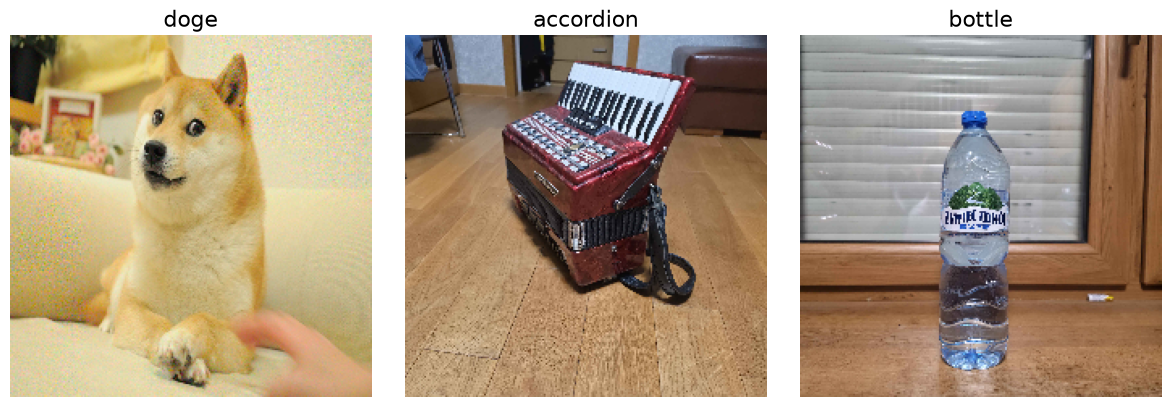

In [2]:
# Assign image titles for your images
image_titles = ['doge', 'accordion', 'bottle']

# Load images and reshape them
img1 = load_img('./doge.png',      target_size=(224, 224))
img2 = load_img('./accordion.jpg', target_size=(224, 224))
img3 = load_img('./bottle.jpg',    target_size=(224, 224))
#We resize the images into size 224 x 224, as the model prefers those sizes. However, if your images are smaller, you can change those values a little bit.

# Convert them to a Numpy array
images = np.asarray([np.array(img1), np.array(img2), np.array(img3)])

# Preparing input data for VGG16
X = preprocess_input(images)

# Rendering
f, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
for i, title in enumerate(image_titles):
    ax[i].set_title(title, fontsize=16)
    ax[i].imshow(images[i])
    ax[i].axis('off')
plt.tight_layout()
plt.show()

We can check if the network correctly recognises the image by running a predict function. Then, we can assign each numerical value of a class a meaning from a dictionary.

In [3]:
# Predict the output (probabilities) of the layer, corresponding to an image
preds = model.predict(X)
best_class = np.argmax(preds, axis=1)

for prediction in decode_predictions(preds, top=3):
    print('Predicted:', prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 608ms/step
Predicted: [('n02115641', 'dingo', np.float32(0.40704736)), ('n02113023', 'Pembroke', np.float32(0.1266095)), ('n02109961', 'Eskimo_dog', np.float32(0.09356421))]
Predicted: [('n02672831', 'accordion', np.float32(0.67120874)), ('n03854065', 'organ', np.float32(0.029521454)), ('n04204347', 'shopping_cart', np.float32(0.02806086))]
Predicted: [('n04557648', 'water_bottle', np.float32(0.9587584)), ('n03983396', 'pop_bottle', np.float32(0.039807744)), ('n02823428', 'beer_bottle', np.float32(0.00088537775))]


# Visualizing heatmaps

The first visualization technique is the one that is useful for understanding which parts of a given image led a convnet to its final classification decision. This is helpful for “debugging” the decision process of a convnet, in particular in case of a classification mistake. It also allows you to locate specific objects in an image.

This general category of techniques is called “Class Activation Map” (CAM) visualization and consists of producing heatmaps of “class activation” over input images. A “class activation” heatmap is a 2D grid of scores associated with a specific output class, computed for every location in any input image, indicating how important each location is with respect to the class considered. For instance, given an image fed into “cat vs. dog” convnet, Class Activation Map visualization allows us to generate a heatmap for the class “cat”, indicating how cat-like different parts of the image are, and likewise for the class “dog”, indicating how dog-like different parts of the image are.

The specific implementation we will use is the one described in paper [Grad-CAM: Why did you say that? Visual Explanations from Deep Networks via Gradient-based Localization](https://arxiv.org/abs/1610.02391).

GradCAM works by using the gradients of the model's final prediction with respect to the activations of the last convolutional layer to generate a heatmap that shows which parts of the input data had the greatest impact on the prediction. Intuitively, one way to understand this trick is that we are weighting a spatial map of “how intensely the input image activates different channels” by “how important each channel is with regard to the class”, resulting in a spatial map of “how intensely the input image activates the class”.

Before we begin, we need to install *tf_keras_vis* library and load four algorithms available in this library, as well as some pre-processing functions. Those methods are:

*   GradCAM
*   GradCAM++
*   ScoreCAM
*   Saliency Maps

If you don't want to use custom library, or if it will be removed in future, you can always write your own GradCAM funtion in Keras using following tutorial: https://keras.io/examples/vision/grad_cam/

In [4]:
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.scorecam import Scorecam
from tf_keras_vis.saliency import Saliency
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

Then, we will define a function that will be used to visualise the output heatmapt generated by all four algorithms.



In [5]:
def visualise_heatmap(map, images):
  f, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
  for i, title in enumerate(image_titles):
      heatmap = np.uint8(cm.jet(map[i])[..., :3] * 255)
      ax[i].set_title(title, fontsize=16)
      ax[i].imshow(images[i])
      ax[i].imshow(heatmap, cmap='jet', alpha=0.5)
      ax[i].axis('off')
  plt.tight_layout()
  plt.show()

# GradCAM
Lets start with basic GradCAM. First, we need to replace the last activation function, in the last layer with linear output. By default, nerual networks used for classification has softmax output. For GradCAM, we need a raw output.

Then, we need to provide a score - a list of classess that we want to visualise. If you want to see other class than the best one, this is the place where you have to change the numbers.

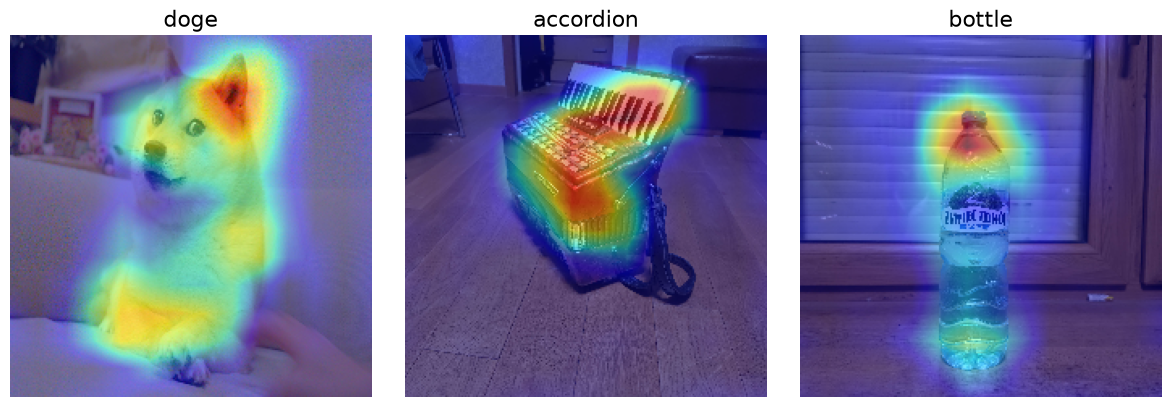

In [6]:
replace2linear = ReplaceToLinear()
score = CategoricalScore(list(best_class))

gradcam = Gradcam(model,
                  model_modifier=replace2linear,
                  clone=True)

cam = gradcam(score,
              X,
              penultimate_layer=-1)

visualise_heatmap(cam, images)

# GradCAM++
The second method will be GradCAM++. In theory, it should provide a better visualisation, better understanding where the object is and covering the larger parto of it. Let's see how it works for your images.

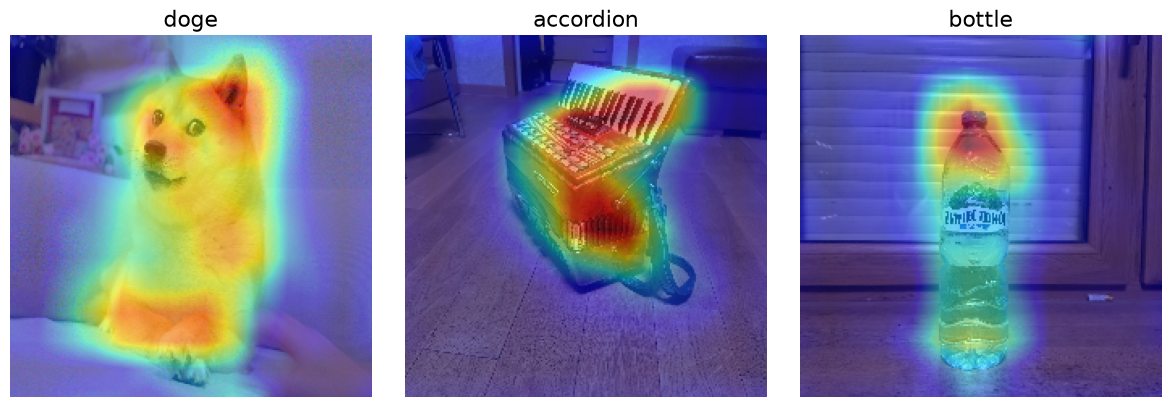

In [7]:
gradcam = GradcamPlusPlus(model,
                          model_modifier=replace2linear,
                          clone=True)

cam = gradcam(score,
              X,
              penultimate_layer=-1)

visualise_heatmap(cam, images)

# ScoreCAM
Now, it is time for ScoreCAM. ScoreCAM is a visualization technique that is similar to GradCAM, but rather than using the gradients, it uses the model's output logits (i.e., the raw output of the model before the softmax activation function is applied) to generate a heatmap that shows which parts of the input data had the greatest impact on the prediction.

In [ ]:
scorecam = Scorecam(model)
cam = scorecam(score, X, penultimate_layer=-1)
visualise_heatmap(cam, images)

W0000 00:00:1793234203.403482  107461 cpu_allocator_impl.cc:174] Allocation of 924844032 exceeds 10% of free system memory.
/home/user/Documents/programming/python/PracticalAspectsOfDeepLearningCourse/lab4/.venv/lib/python3.14/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=('Tensor(shape=(32, 224, 224, 3))',)
  warnings.warn(msg)


45/48 ━━━━━━━━━━━━━━━━━━━━ 13s 4s/step

# Saliency Maps
The last method would be Saliency Maps. They are the simpliest of those methods, basicaly displaying raw values of neural network output gradients.

In [ ]:
saliency = Saliency(model, model_modifier=replace2linear, clone=True)
saliency_map = saliency(score, X)
visualise_heatmap(saliency_map, images)

Finally, we can smooth those outputs a little, to make them visually more apealing.

In [ ]:
saliency_map = saliency(score, X, smooth_samples=20, smooth_noise=0.20)
visualise_heatmap(saliency_map, images)

# Bonus tasks

This is the end of the first task. You can now try to do some bonus tasks:
1. You can test the performance of all this methods on images that have more than one object. Check if the network classifies the image based on just one objcect, or all of them.
2. You can visualise a heatmap that correspond to a different class than the class with the highest probability - for example the second best, 5th best, 10th best etc.
3. You can test the performance on an image that has two contradictory object, for example dog and cat.

In [ ]:
for i, prediction in enumerate(decode_predictions(preds, top=5)):
    print(f"\n{image_titles[i]}:")
    for _, label, probability in prediction:
        print(f"  {label}: {probability:.3f}")


gradcam = Gradcam(model, model_modifier=replace2linear, clone=True)


rank = 1
ranked_classes = np.argsort(preds, axis=1)[:, ::-1]
target_classes = ranked_classes[:, rank]

score = CategoricalScore(list(target_classes))
cam = gradcam(score, X, penultimate_layer=-1)
visualise_heatmap(cam, images)


for label, class_index in [("tabby cat", 281), ("golden retriever", 207)]:
    score = CategoricalScore([class_index])
    cam = gradcam(score, X[0:1], penultimate_layer=-1)

    heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)
    plt.figure(figsize=(5, 5))
    plt.imshow(images[0])
    plt.imshow(heatmap, cmap="jet", alpha=0.5)
    plt.title(f"Grad-CAM: {label}")
    plt.axis("off")
    plt.show()

# Visualizing intermediate activations

We will introduce one more visualization technique. Visualizing intermediate activations consists of displaying the feature maps that are output by various convolution and pooling layers in a network, given a certain input (the output of a layer is often called its “activation”, the output of the activation function). This gives a view into how input is decomposed into the different filters learned by the network. These feature maps we want to visualize have 3 dimensions: width, height, and depth (channels). Each channel encodes relatively independent features, so the proper way to visualize these feature maps is by independently plotting the contents of every channel, as a 2D image.

In [ ]:
layer_outputs = [layer.output for layer in model.layers]
activation_model = models.Model(model.input, layer_outputs)

X_reshaped = X[0:1]
activations = activation_model.predict(X_reshaped, verbose=0)

target_layer = "block3_conv1"
images_per_row = 16

for layer, layer_activation in zip(model.layers, activations):
    if layer.name == target_layer:
        n_features = layer_activation.shape[-1]
        height, width = layer_activation.shape[1:3]
        n_cols = min(images_per_row, n_features)
        n_rows = int(np.ceil(n_features / n_cols))

        display_grid = np.zeros((n_rows * height, n_cols * width))

        for channel in range(n_features):
            row = channel // n_cols
            col = channel % n_cols

            channel_image = layer_activation[0, :, :, channel].astype("float32")
            channel_min = channel_image.min()
            channel_max = channel_image.max()

            if channel_max > channel_min:
                channel_image = (channel_image - channel_min) / (channel_max - channel_min)
            else:
                channel_image = np.zeros_like(channel_image)

            display_grid[
                row * height:(row + 1) * height,
                col * width:(col + 1) * width
            ] = channel_image

        plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
        plt.imshow(display_grid, aspect="auto", cmap="viridis")
        plt.title(f"Activations: {target_layer}")
        plt.axis("off")
        plt.show()
        break
else:
    print(f"Layer {target_layer!r} was not found. Check the model summary for layer names.")


# Additional tasks

This is the end of the task. You can now do some experiments using the code and try to better understand our model.
1. Experiment with different layer names to get different visualisations.
2. Try some names from the early layers, some from the middle layers and some from the final conv layers.
3. Ask yourself if you understand how the network works. Do you know why there is a different number of images for different layers? Do you know why some images resemble the input and some not?

In [ ]:
layers_to_compare = ["block1_conv1", "block3_conv1", "block5_conv3"]
input_index = 0

activations = activation_model.predict(
    X[input_index:input_index + 1],
    verbose=0
)

fig, axes = plt.subplots(
    len(layers_to_compare), 8,
    figsize=(16, 6)
)

for row, layer_name in enumerate(layers_to_compare):
    layer_index = next(
        i for i, layer in enumerate(model.layers)
        if layer.name == layer_name
    )
    feature_maps = activations[layer_index][0]

    for channel in range(8):
        ax = axes[row, channel]
        ax.imshow(feature_maps[:, :, channel], cmap="viridis")
        ax.axis("off")

        if channel == 0:
            ax.set_ylabel(layer_name, rotation=0, labelpad=75, va="center")

plt.suptitle(f"Feature maps for {image_titles[input_index]}")
plt.tight_layout()
plt.show()
